## <span style="color:purple"> Graph Seasonal Temperature-Salinity Plots for Each MicroCAT </span>

<span style="color:purple"> These graphs will plot temperature against salinity data from across each season of each year. The purpose of this is to visually inspect the composition of the water masses that are recorded at a particular MicroCAT, which should allow for some interpretation of their source. </span>

### <span style="color:purple"> Plotting function </span>

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import gsw

# Define global colour mapping for each year to ensure consistency across boreholes and MicroCATs
colours = {
    2001: "tab:blue",   2002: "tab:orange", 2003: "tab:green",
    2004: "tab:red",    2005: "tab:purple", 2006: "tab:brown",
    2007: "tab:pink",   2008: "tab:olive",  2009: "tab:cyan",
    2010: "darkblue",   2011: "crimson",    2012: "teal",
    2013: "goldenrod",
}

# Define a dictionary mapping each season to their month numbers
seasons = {
    "Summer: Dec–Feb": [12, 1, 2],
    "Autumn: Mar–May": [3, 4, 5],
    "Winter: Jun–Aug": [6, 7, 8],
    "Spring: Sep–Nov": [9, 10, 11],
}

# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
avg_pressures = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 653.6,    "4054": 861.5,   "3883": 1211.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}

def plot_season(df, borehole, cat, ylim_temp=None, xlim_sal=None):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey="row")

    # Create a mask to filter the specified borehole and cat
    full_year = df[(df["borehole"] == borehole) & (df["cat"] == cat)].copy()

    for col, (season_name, months) in enumerate(seasons.items()):
        ax = axes[col]
        
        # Create a mask to filter the dataframe for the specified borehole, cat and months of the year
        mask = (df["borehole"] == borehole) & (df["cat"] == cat) & (df["time"].dt.month.isin(months))
        sub = df[mask].copy()
    
        # Extract year from the time column
        sub["year"] = sub["time"].dt.year

        # Create a boolean variable that represents where the season
        # For Dec-Feb: only done if Dec is in the season being plotted 
        if 12 in months:
            # Create to filter the dataframe to just December timestamps
            dec_mask = sub["time"].dt.month == 12
            # Assign December to the following year's season
            sub.loc[dec_mask, "year"] = sub.loc[dec_mask, "time"].dt.year + 1

        # Get the unique years in the subset
        years = sorted(sub["year"].unique())

        for year in years:
            # Filter the subset for the current year
            year_data = sub[sub["year"] == year]
            
            # Plot raw data
            ax.scatter(year_data["absolute_salinity"], year_data["conservative_temperature"], color=colours[year], label=str(year) if col == 0 else "_", s=2)

        if col == 0:
            ax.set_ylabel(r"$\Theta$ (°C)")
        ax.set_xlabel(r"$\mathrm{S_{A} \ g \ kg^{-1}}$")

        ax.set_title(season_name)

        if ylim_temp is not None: ax.set_ylim(*ylim_temp)
        if xlim_sal  is not None: ax.set_xlim(*xlim_sal)

        if col > 0:
            ax.tick_params(left=False, labelleft=False)

        # Next we need to plot relevant overlays to aid interpretation of T-S plots
        # Define the range of temp and salinity over which we will plot these
        salinity_range = np.linspace(xlim_sal[0], xlim_sal[1], 100)
        temp_range = np.linspace(ylim_temp[0], ylim_temp[1], 100)
        
        # 1. Freezing point temperature line at 0 dbar (saturation fraction = 0)
        CT_freeze_0 = gsw.CT_freezing(salinity_range, 0, 0)
        ax.plot(salinity_range, CT_freeze_0, "b--", lw=1, label=r"$\Theta_f$ (0 dbar)")
            
        # 2. Freezing point temperature line at average mooring pressure (determined at deployment)
        CT_freeze_p = gsw.CT_freezing(salinity_range, avg_pressures[f"{cat}"], 0)
        ax.plot(salinity_range, CT_freeze_p, "b-", lw=1, label=f"$\Theta_f$ ({avg_pressures[f"{cat}"]:.0f} dbar)")
            
        # 3. Isopycnals (potential density anomaly contours) referenced to 0 dbar
        # This is the anomaly, i.e. density minus 1000 kg/m^3 (appropriate for shallowish waters)
        salinity_grid, temp_grid = np.meshgrid(salinity_range, np.linspace(*ax.get_ylim(), 100))
        sigma = gsw.sigma0(salinity_grid, temp_grid)
        cs = ax.contour(salinity_grid, temp_grid, sigma, colors="grey", linestyles=":", linewidths=0.6)
        ax.clabel(cs, inline=True, fontsize=7, fmt="%.2f")

        # 4. Meltwater (Gade) line — anchored at warmest/saltiest source water
        salinity_source = sub["absolute_salinity"].quantile(0.95)
        temp_source = sub["conservative_temperature"].quantile(0.95)
        # Ice temperature: in situ freezing temperature at source pressure
        t_ice = gsw.t_freezing(salinity_source, avg_pressures[f"{cat}"], 0)
        
        # Get dSA/dCT from gsw, invert to get dCT/dSA for plotting
        dSA_dCT = gsw.ice.melting_ice_SA_CT_ratio(salinity_source, temp_source, avg_pressures[f"{cat}"], t_ice)
        slope = 1 / dSA_dCT  # dCT/dSA
        
        CT_gade = temp_source + slope * (salinity_range - salinity_source)
        ax.plot(salinity_range, CT_gade, "r-", lw=1.5, label="Meltwater mixing line")
        ax.plot(salinity_source, temp_source, "ro", markersize=6)


    # Single legend on the first column to avoid clutter
    axes[0].legend(ncols=2, fontsize=8, loc="best")

    # Extract the position of the iterated MicroCAT in the water column at its respective borehole
    position = full_year["water_column_position"].iloc[0]

    fig.suptitle(f"{borehole} {position.capitalize()} MicroCAT cat{cat}: Temperature vs. Salinity", fontsize=14, y=1.00)
        
    plt.tight_layout()
    plt.show()

<>:91: SyntaxWarning: invalid escape sequence '\T'
<>:91: SyntaxWarning: invalid escape sequence '\T'
/var/folders/m1/85gcq97s2ys6j5qqm0sw6bf40000gn/T/ipykernel_34465/2596603083.py:91: SyntaxWarning: invalid escape sequence '\T'
  ax.plot(salinity_range, CT_freeze_p, "b-", lw=1, label=f"$\Theta_f$ ({avg_pressures[f"{cat}"]:.0f} dbar)")


### <span style="color:purple"> Plot seasonal temperature vs. salinity plots for each borehole/cat </span>

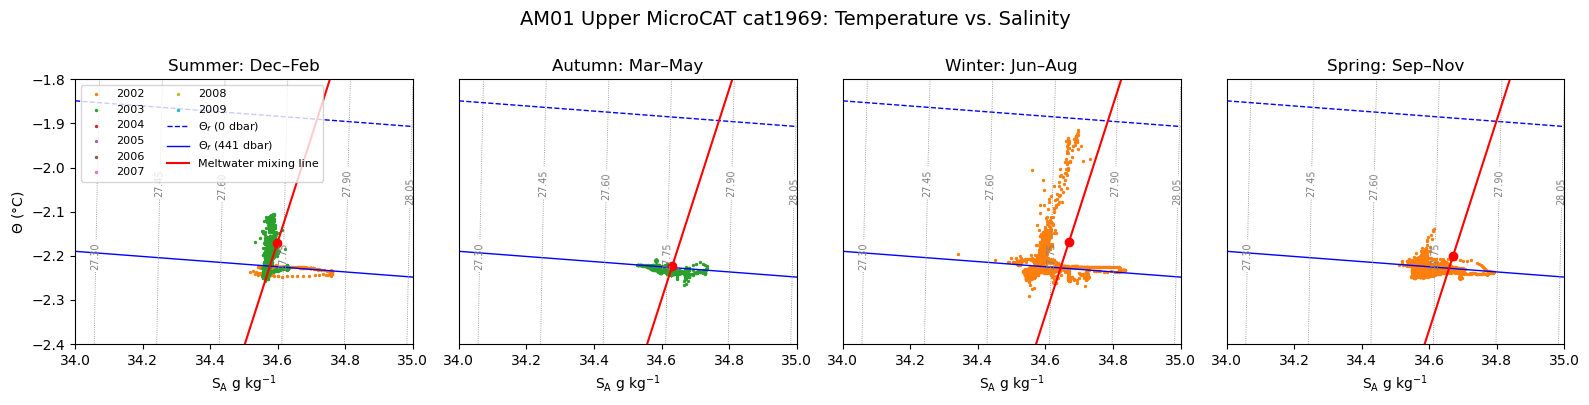

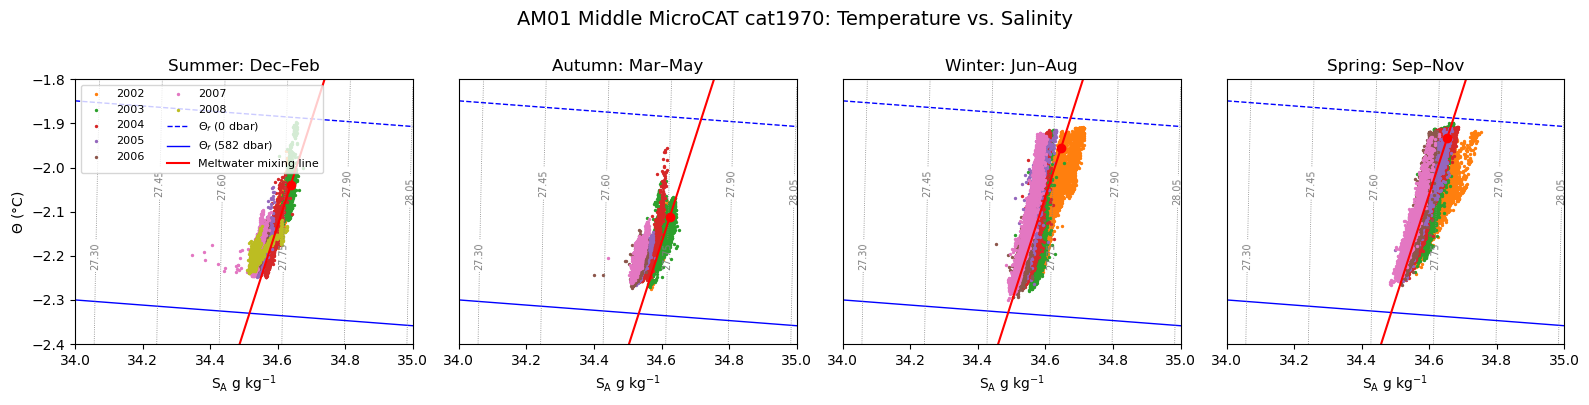

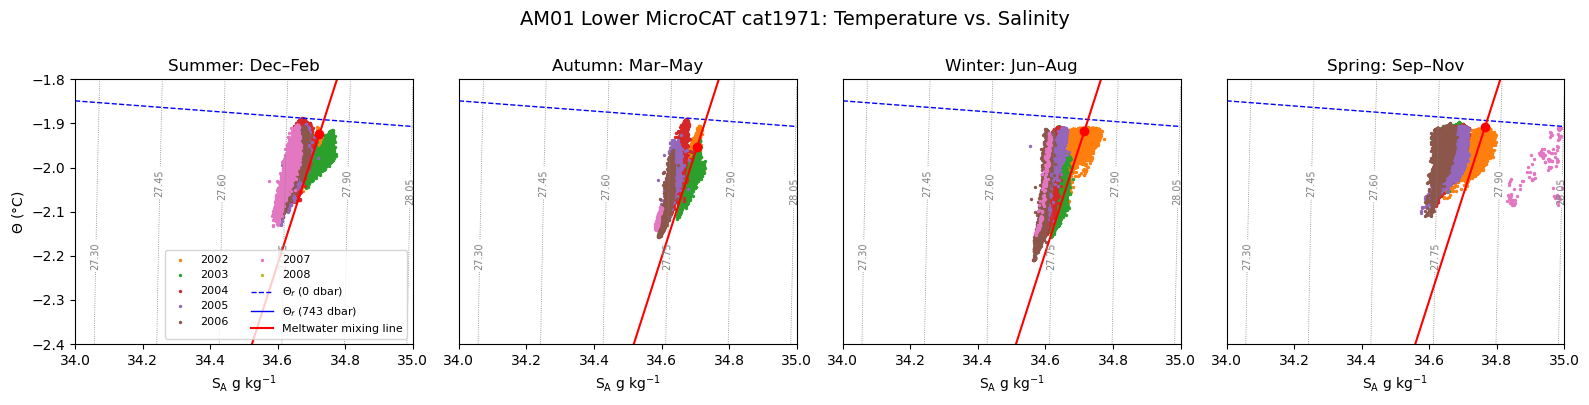

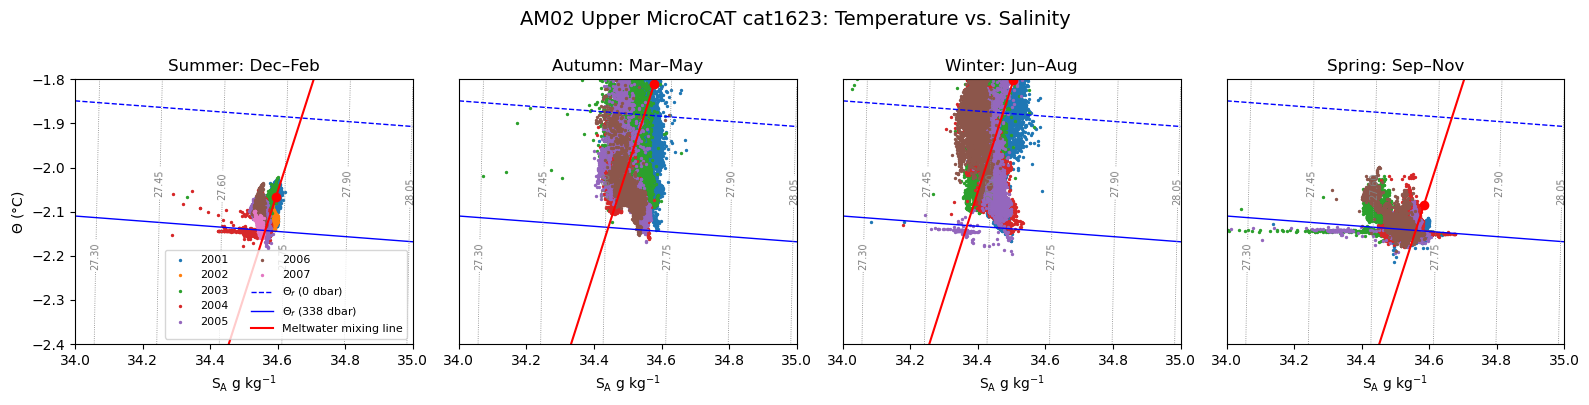

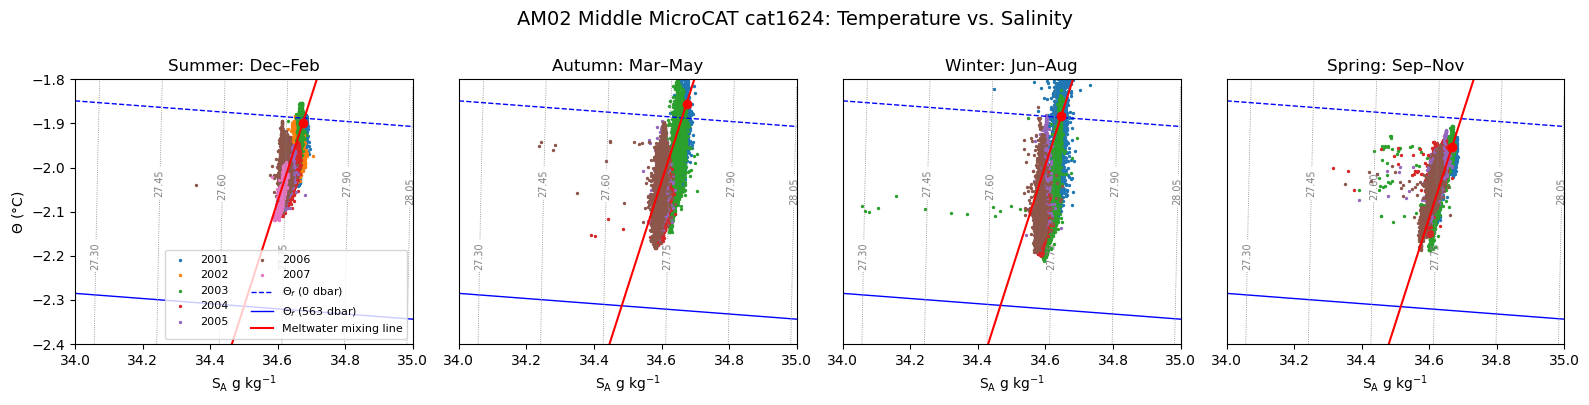

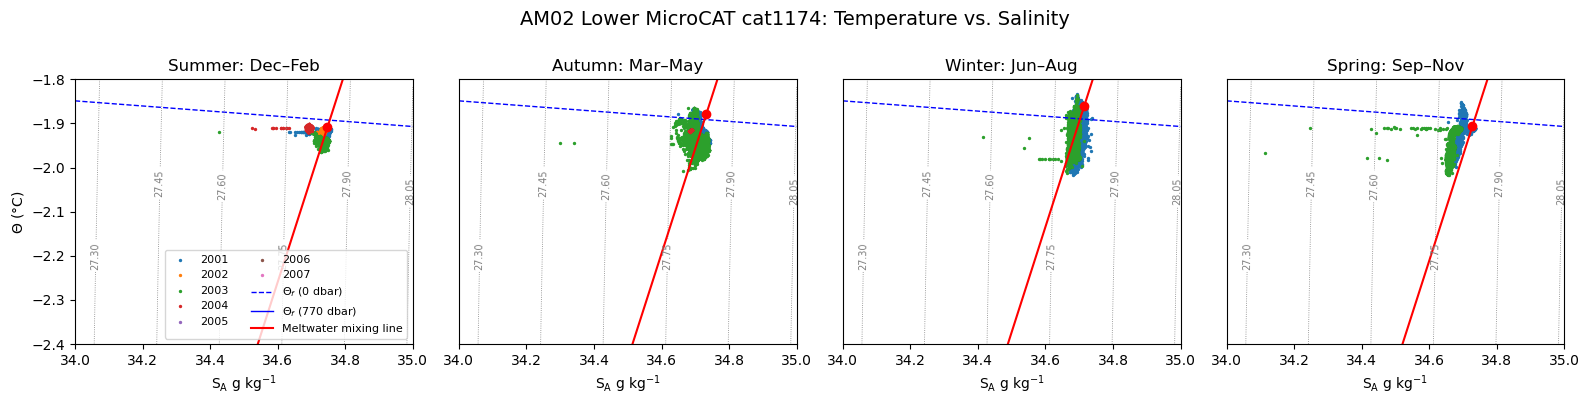

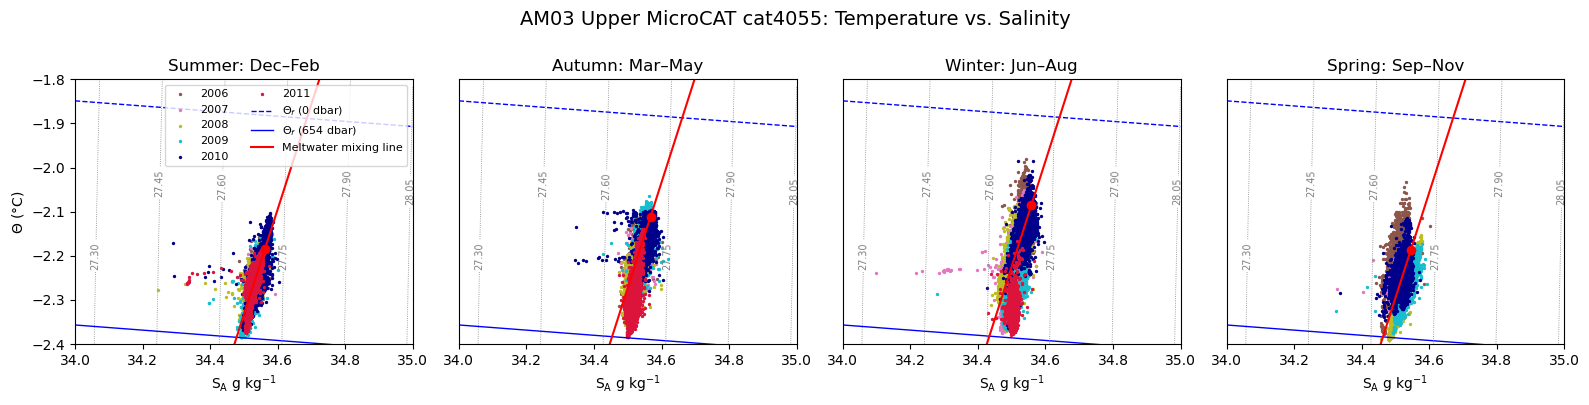

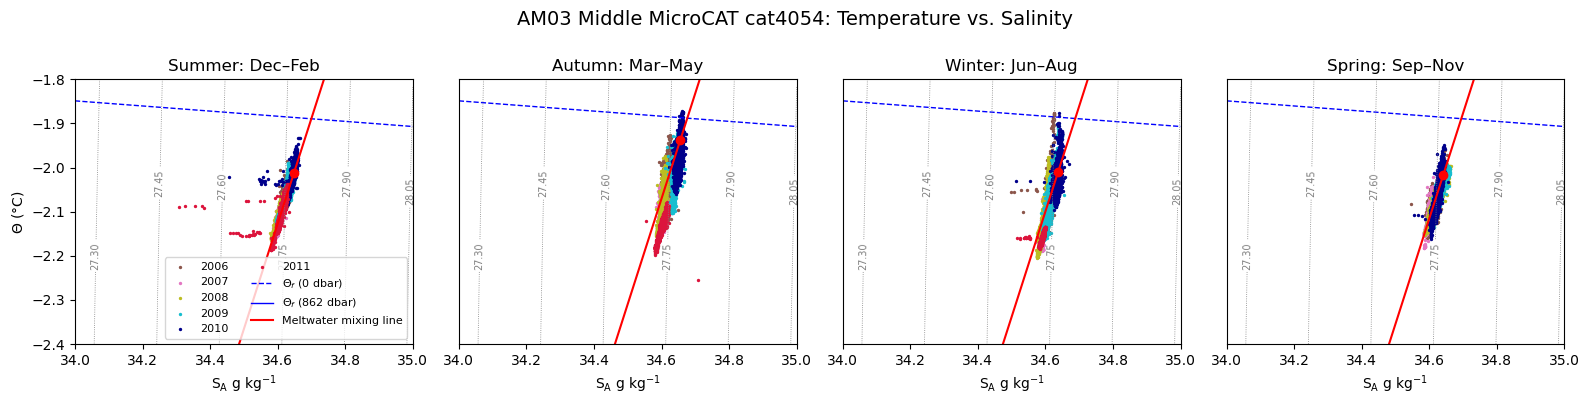

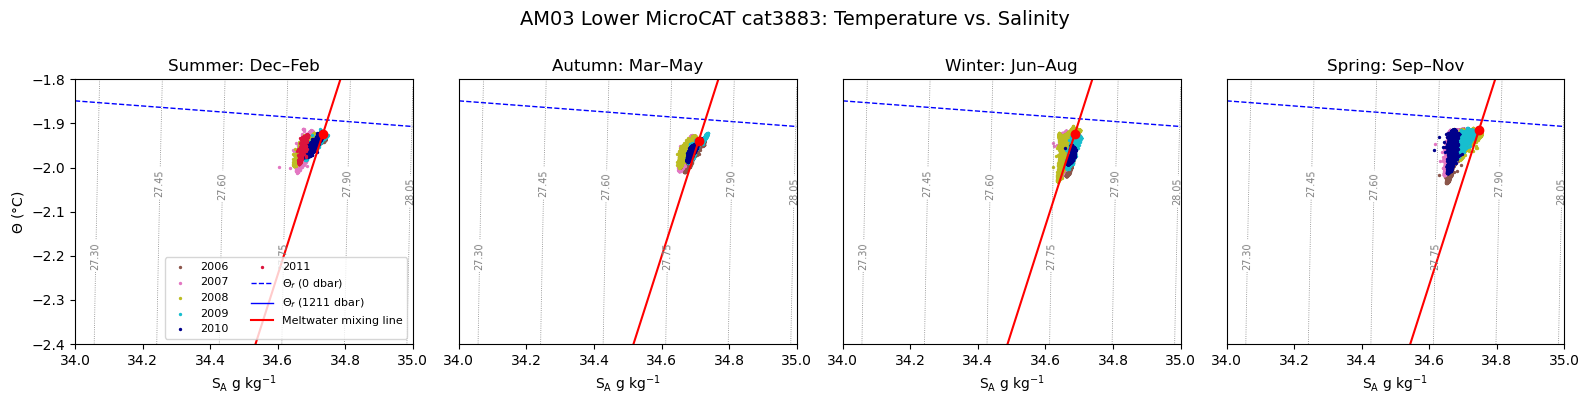

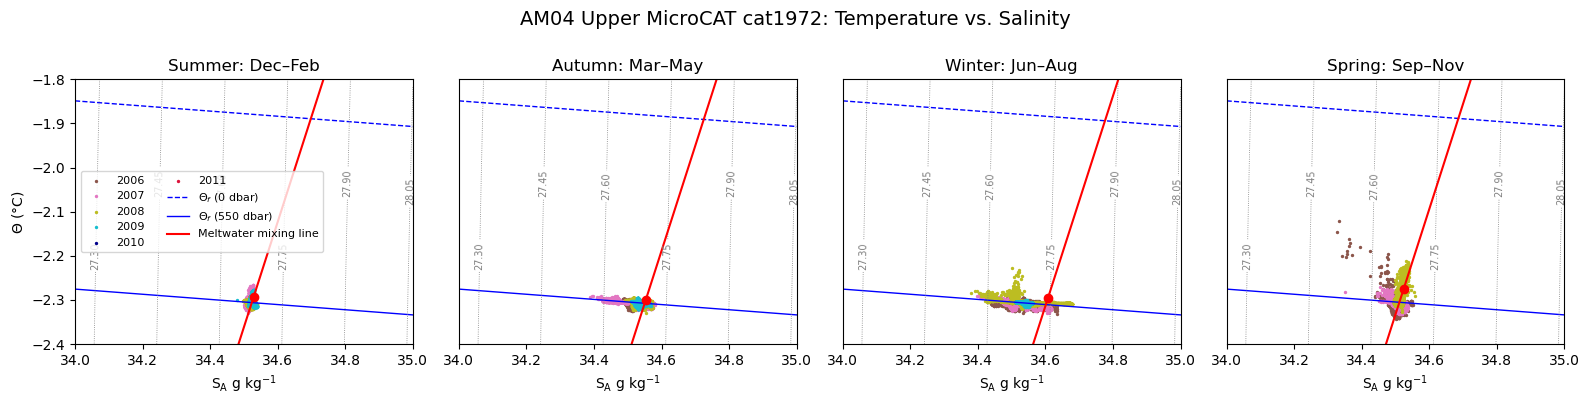

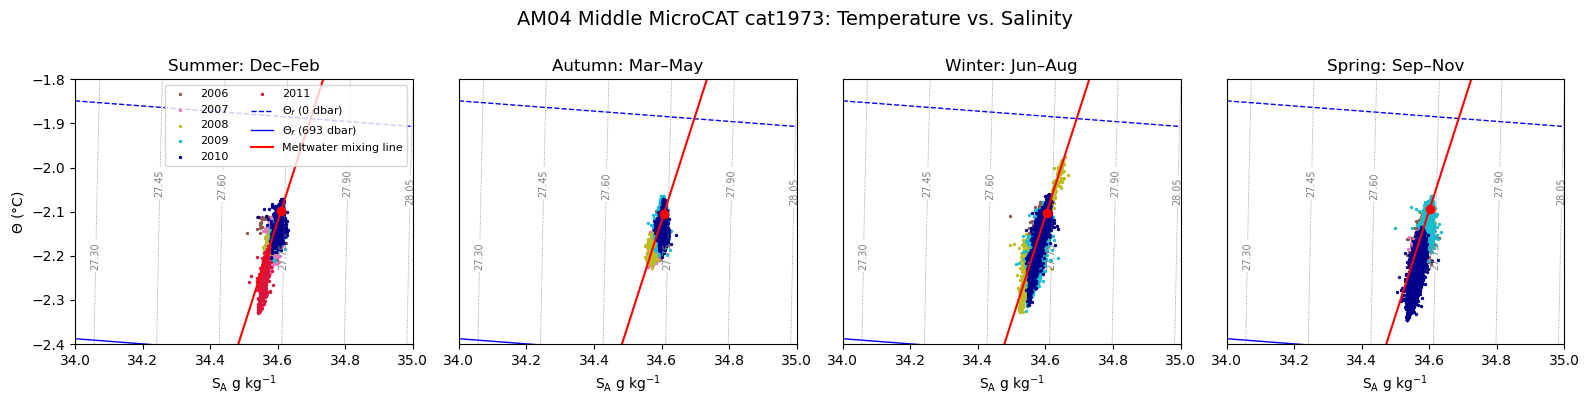

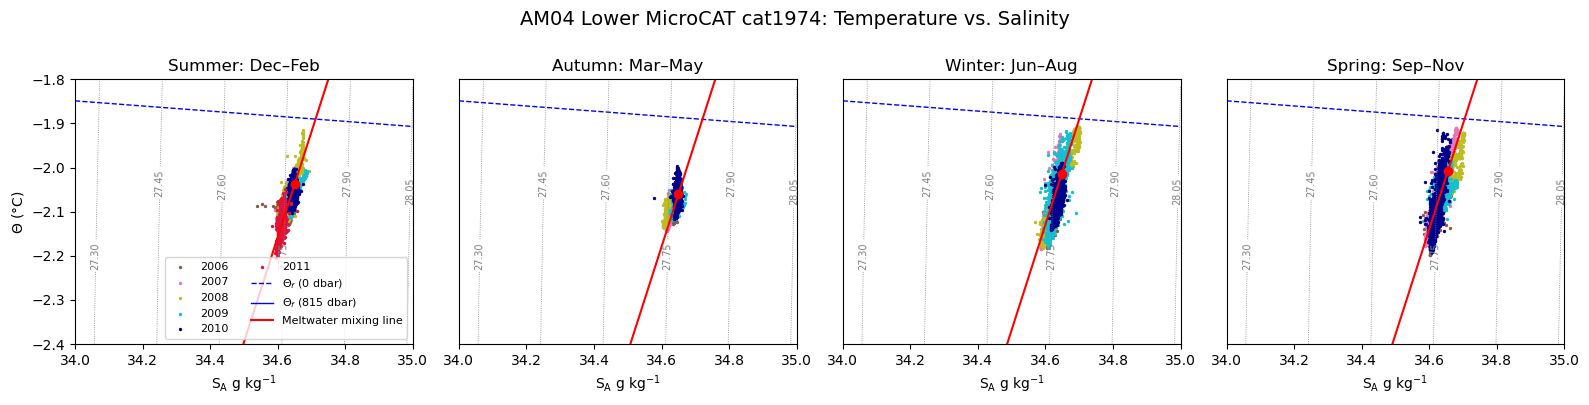

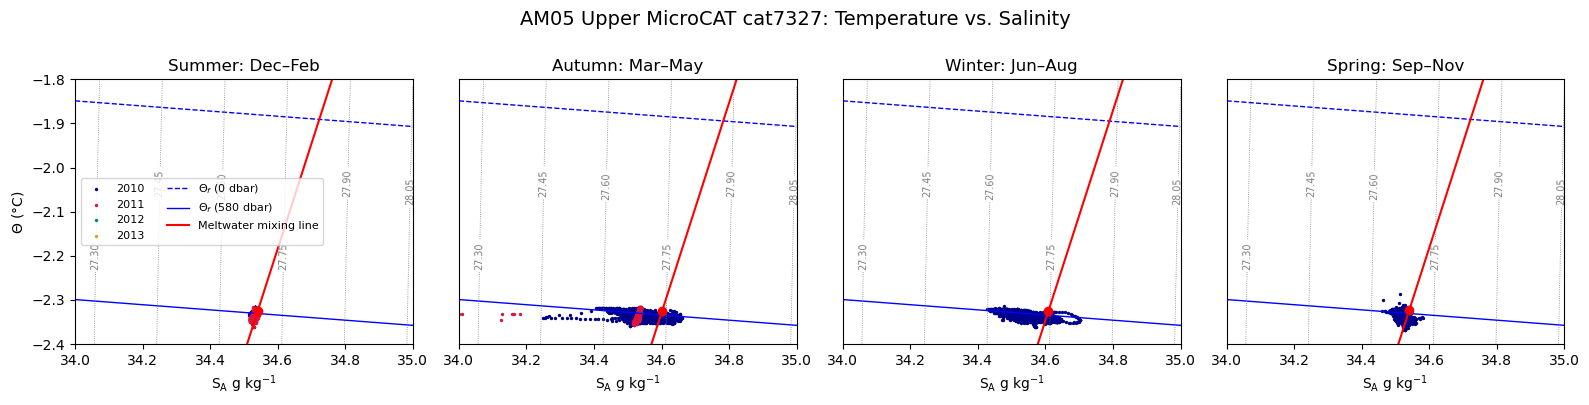

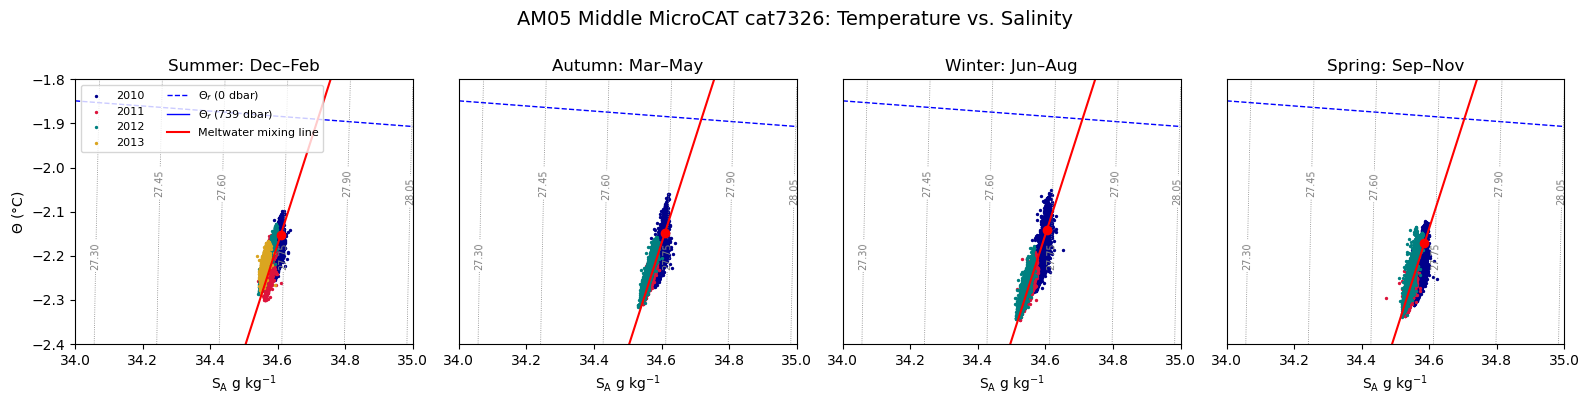

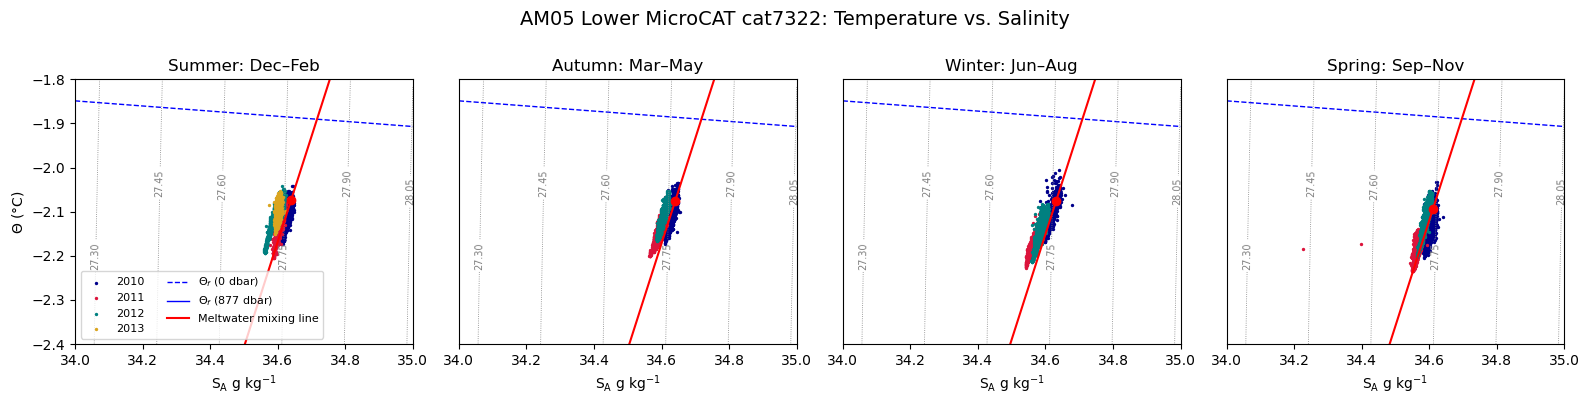

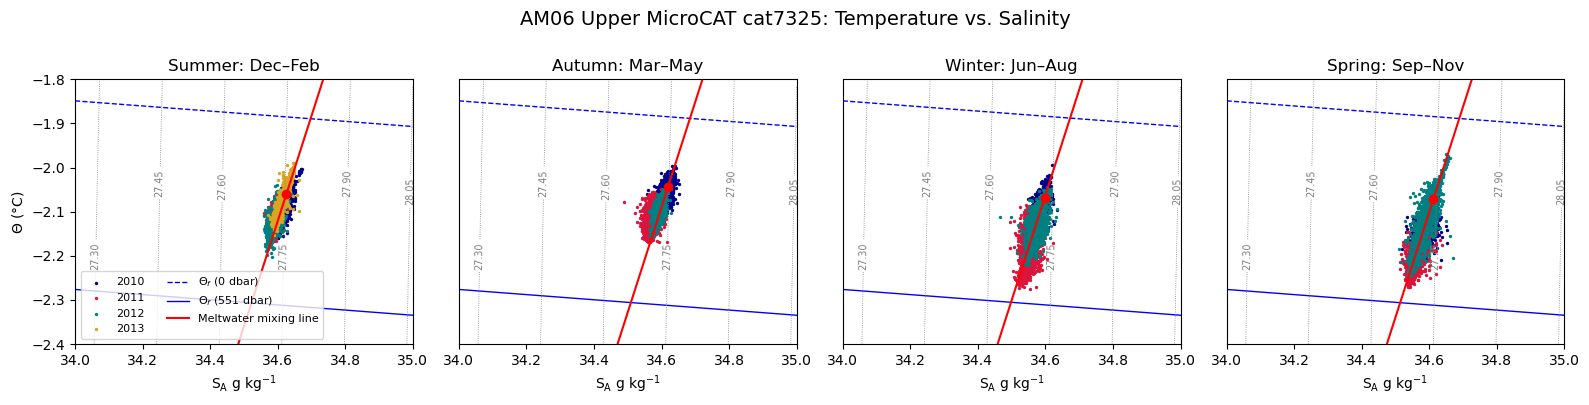

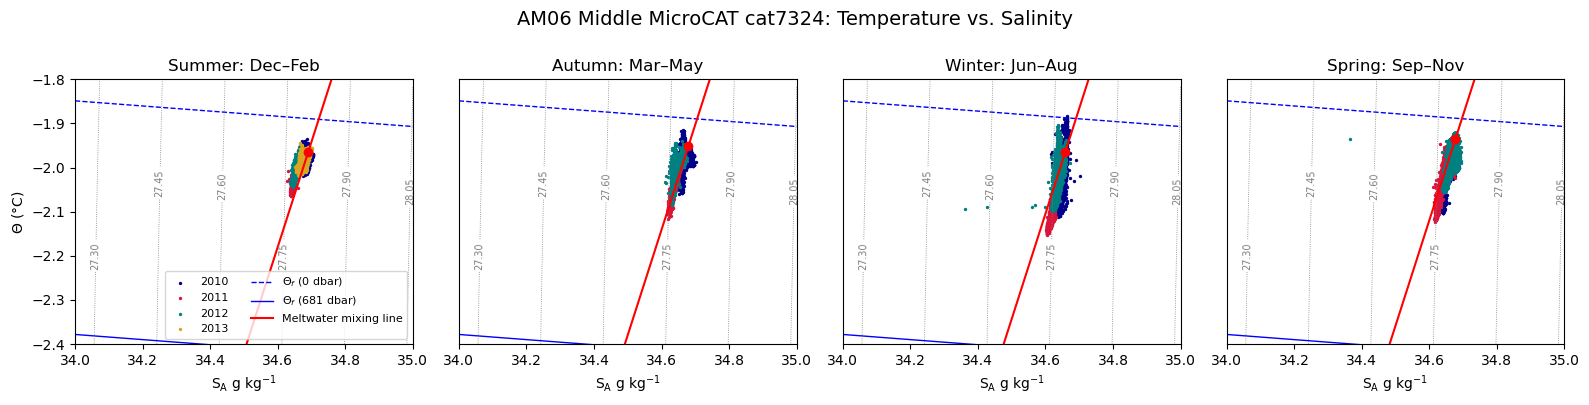

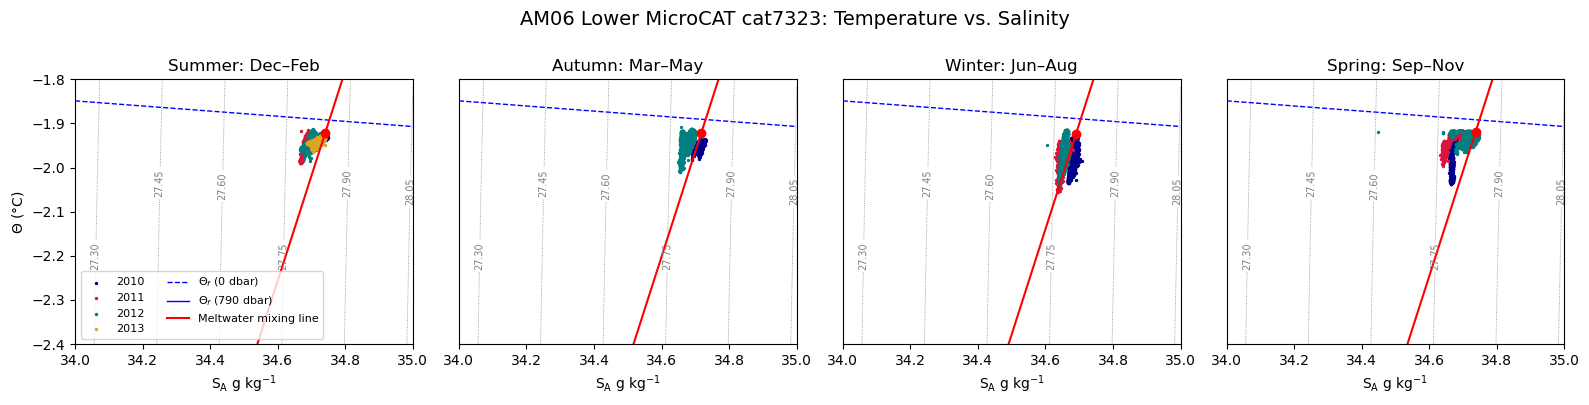

In [25]:
df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Define the limits for plots of temperature and salinity
ylim_temp = (-2.4, -1.8)
xlim_sal = (34, 35)

boreholes = sorted(df["borehole"].unique())

for borehole in boreholes:
    df_bh = df[df["borehole"] == borehole]

    # Build a list to force ordered plotting of the upper, then middle, then lower MicroCAT
    position_order = ["upper", "middle", "lower"]

    for position in position_order:
        cats = df_bh[df_bh["water_column_position"] == position]["cat"].unique()

        for cat in cats:
            plot_season(df, borehole, cat, ylim_temp=ylim_temp, xlim_sal=xlim_sal)